# Examen ICCD753 Recuperación de Información

## 1. Objetivo

Desarrollar un sistema de recuperación de información sobre un corpus asignado. El sistema deberá indexar los documentos, recuperar y ordenar resultados mediante TF-IDF con similitud coseno y BM25, y exponer la búsqueda como un servicio web publicado en internet.

Se evaluará el servicio enviando consultas desde un cliente (p.ej. Postman) y contrastando los resultados con los juicios de relevancia (*qrels*) del corpus.

## 2. Corpus asignado

Cada estudiante recibirá un conjunto de datos. Todos contienen documentos, consultas y qrels. Se utilizarán los identificadores originales de los documentos para que los resultados puedan evaluarse.

| Corpus | Documentos y consultas | Qrels |
| --- | --- | --- |
| NFCorpus | [BeIR/nfcorpus](https://huggingface.co/datasets/BeIR/nfcorpus) | [BeIR/nfcorpus-qrels](https://huggingface.co/datasets/BeIR/nfcorpus-qrels) |
| SciFact | [BeIR/scifact](https://huggingface.co/datasets/BeIR/scifact) | [BeIR/scifact-qrels](https://huggingface.co/datasets/BeIR/scifact-qrels) |

## 3. Requisitos del sistema

### 3.1. Preparación e indexación

El sistema deberá:

1. Cargar e indexar los documentos del corpus asignado.
2. Aplicar y documentar las decisiones de preprocesamiento: tokenización, normalización, eliminación de stopwords y stemming o lematización.
3. Construir un vocabulario y un índice invertido que permita recuperar documentos.
4. Conservar la relación entre cada documento indexado y su identificador original.

La unidad de evaluación será el documento original, porque los qrels relacionan consultas con identificadores de documentos. No se debe dividir el texto en fragmentos.

### 3.2. Modelos de recuperación

Para cualquier consulta de texto, el sistema deberá producir dos rankings independientes:

- TF-IDF con similitud coseno.
- BM25.

Cada ranking deberá ordenar los documentos por puntuación de relevancia y permitir solicitar los primeros `k` resultados.

### 3.3. Servicio web

El sistema deberá estar publicado en internet y ofrecer, como mínimo, los siguientes endpoints:

**Comprobación de disponibilidad**

```http
GET /health
```

**Búsqueda**

```http
POST /search
Content-Type: application/json
```

Ejemplo de solicitud:

```json
{
  "query": "texto de la consulta",
  "model": "bm25",
  "top_k": 10
}
```

El campo `model` deberá aceptar `bm25` y `tfidf`. Una respuesta tendrá esta estructura:

```json
{
  "model": "bm25",
  "results": [
    {
      "rank": 1,
      "document_id": "identificador_original",
      "score": 8.42,
      "title": "Título, si está disponible",
      "snippet": "Fragmento del documento recuperado"
    }
  ]
}
```

Los resultados deberán estar ordenados de mayor a menor puntuación, no contener documentos duplicados y respetar el valor solicitado de `top_k`. El servicio debe aceptar consultas que el estudiante no conozca de antemano.

## 4. Evaluación de la recuperación

Cada estudiante debe evaluar ambos modelos con consultas de la partición `test` y sus qrels. Presentará, como mínimo:

- Precision@10.
- Recall@10.
- NDCG@10.
- Una comparación de los resultados de TF-IDF y BM25.

En el Jupyter Notebook se deberá indicar qué consultas se utilizaron y permitir reproducir los cálculos. La evaluación del docente podrá utilizar otras consultas del mismo conjunto.

## 5. Prueba del docente

El docente accederá a la URL entregada y realizará solicitudes desde un cliente de web service para comprobar:

1. La disponibilidad del servicio.
2. El funcionamiento de TF-IDF y BM25.
3. El formato, orden y validez de los resultados.
4. La correspondencia de los `document_id` con el corpus y los qrels.
5. La respuesta ante consultas no incluidas en los ejemplos de entrega.

## 6. Entregables

Cada estudiante entregará:

1. La URL pública del servicio web, accesible durante el período de revisión.
2. El código en Jupyter Notebook con los resultados de la ejecución de cada bloque de código, incluyendo los resultados de las métricas de evaluación de los modelos de recuperación.

Se evaluará que ambos modelos funcionen correctamente y que cada estudiante interprete sus resultados.

## 1. Configuración del entorno e importaciones

En este bloque verificamos e instalamos únicamente las dependencias faltantes (útil en entornos limpios como Google Colab) y configuramos las librerías estándar de procesamiento, visualización y servicio web.

In [9]:
import importlib.util
import math
import os
import platform
import re
import shutil
import socket
import subprocess
import sys
import tempfile
import threading
import time
import unicodedata
from collections import Counter, defaultdict

os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"

REQUIRED_PACKAGES = {
    "numpy": "numpy",
    "pandas": "pandas",
    "huggingface_hub": "huggingface_hub",
    "pyarrow": "pyarrow",
    "nltk": "nltk",
    "sklearn": "scikit-learn",
    "fastapi": "fastapi",
    "uvicorn": "uvicorn",
    "requests": "requests",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
}

missing = [pkg for mod, pkg in REQUIRED_PACKAGES.items() if importlib.util.find_spec(mod) is None]
if missing:
    print(f"Instalando dependencias faltantes: {missing}")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
else:
    print("Todas las dependencias requeridas ya están instaladas.")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
import uvicorn
from fastapi import FastAPI, HTTPException
from fastapi.middleware.cors import CORSMiddleware
from huggingface_hub import hf_hub_download
from nltk.stem import SnowballStemmer
from pydantic import BaseModel, Field
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 110)

print(f"Python: {sys.version.split()[0]} | Sistema operativo: {platform.system()} ({platform.machine()})")

Todas las dependencias requeridas ya están instaladas.
Python: 3.14.6 | Sistema operativo: Windows (AMD64)


## 2. Carga y exploración del corpus NFCorpus

Cargamos directamente desde Hugging Face Hub los archivos oficiales de **NFCorpus**:
- `BeIR/nfcorpus`: documentos (`corpus/corpus-00000-of-00001.parquet`) y consultas (`queries/queries-00000-of-00001.parquet`).
- `BeIR/nfcorpus-qrels`: juicios de relevancia de la partición `test` (`test.tsv`).

Cada fila de `corpus` corresponde a un documento científico/médico completo con su identificador original (`_id`), título (`title`) y resumen/texto (`text`). No se fragmenta ningún documento, garantizando correspondencia 1:1 con los `qrels`.

In [10]:
corpus_path = hf_hub_download(
    repo_id="BeIR/nfcorpus",
    filename="corpus/corpus-00000-of-00001.parquet",
    repo_type="dataset",
)
queries_path = hf_hub_download(
    repo_id="BeIR/nfcorpus",
    filename="queries/queries-00000-of-00001.parquet",
    repo_type="dataset",
)
qrels_test_path = hf_hub_download(
    repo_id="BeIR/nfcorpus-qrels",
    filename="test.tsv",
    repo_type="dataset",
)

corpus_df = pd.read_parquet(corpus_path)
queries_df = pd.read_parquet(queries_path)
qrels_test_df = pd.read_csv(qrels_test_path, sep="\t")

# Normalizamos tipos a string / int y verificamos integridad referencial
corpus_df["_id"] = corpus_df["_id"].astype(str)
corpus_df["title"] = corpus_df["title"].fillna("").astype(str)
corpus_df["text"] = corpus_df["text"].fillna("").astype(str)

queries_df["_id"] = queries_df["_id"].astype(str)
queries_df["text"] = queries_df["text"].fillna("").astype(str)

qrels_test_df["query-id"] = qrels_test_df["query-id"].astype(str)
qrels_test_df["corpus-id"] = qrels_test_df["corpus-id"].astype(str)
qrels_test_df["score"] = qrels_test_df["score"].astype(int)

# Diccionarios auxiliares para acceso rápido
query_text_map = dict(zip(queries_df["_id"], queries_df["text"]))
qrels_test = defaultdict(dict)
for row in qrels_test_df.itertuples(index=False):
    if row.score > 0:
        qrels_test[row[0]][row[1]] = int(row.score)

test_qids = sorted(qrels_test.keys())

assert corpus_df["_id"].is_unique, "Existen document_id duplicados en el corpus"
assert len(set(test_qids) - set(query_text_map.keys())) == 0, "Faltan consultas de test en queries"
assert len(set(qrels_test_df["corpus-id"]) - set(corpus_df["_id"])) == 0, "Faltan documentos de qrels en corpus"

summary_df = pd.DataFrame([
    {"Componente": "Documentos en corpus (NFCorpus)", "Cantidad": len(corpus_df)},
    {"Componente": "Consultas totales en queries", "Cantidad": len(queries_df)},
    {"Componente": "Consultas únicas en partición test", "Cantidad": len(test_qids)},
    {"Componente": "Juicios de relevancia (qrels test)", "Cantidad": len(qrels_test_df)},
    {"Componente": "Qrels con grado 1 (relevante)", "Cantidad": int((qrels_test_df["score"] == 1).sum())},
    {"Componente": "Qrels con grado 2 (muy relevante)", "Cantidad": int((qrels_test_df["score"] == 2).sum())},
])
display(summary_df)

print("\nEjemplo de 3 documentos del corpus:")
display(corpus_df[["_id", "title", "text"]].head(3))

print("\nEjemplo de 5 consultas de la partición test:")
sample_queries_df = pd.DataFrame([
    {"query_id": qid, "query_text": query_text_map[qid], "num_relevantes_qrels": len(qrels_test[qid])}
    for qid in test_qids[:5]
])
display(sample_queries_df)

,Componente,Cantidad
0,Documentos en corpus (NFCorpus),3633
1,Consultas totales en queries,3237
2,Consultas únicas en partición test,323
3,Juicios de relevancia (qrels test),12334
4,Qrels con grado 1 (relevante),11758
5,Qrels con grado 2 (muy relevante),576



Ejemplo de 3 documentos del corpus:


,_id,title,text
0,MED-10,Statin Use and Breast Cancer Survival: A Nationwide Cohort Study from Finland,"Recent studies have suggested that statins, an established drug group in the prevention of cardiovascular ..."
1,MED-14,Statin use after diagnosis of breast cancer and survival: a population-based cohort study.,"BACKGROUND: Preclinical studies have shown that statins, particularly simvastatin, can prevent growth in b..."
2,MED-118,Alkylphenols in human milk and their relations to dietary habits in central Taiwan.,The aims of this study were to determine the concentrations of 4-nonylphenol (NP) and 4-octylphenol (OP) i...



Ejemplo de 5 consultas de la partición test:


,query_id,query_text,num_relevantes_qrels
0,PLAIN-1008,deafness,5
1,PLAIN-1018,DHA,60
2,PLAIN-102,Stopping Heart Disease in Childhood,24
3,PLAIN-1028,dietary scoring,1
4,PLAIN-1039,domoic acid,2


## 3. Preprocesamiento de texto (Decisiones documentadas)

Para indexar documentos biomédicos y consultas en inglés sin fragmentar los textos originales, se diseñó el siguiente pipeline determinista:

1. **Unidad documental (`title + " " + text`):** Cada documento se representa concatenando su título y su cuerpo completo (`title + " " + text`), conservando íntegro su identificador original `_id`.
2. **Normalización:** Se aplica normalización Unicode `NFKC`, conversión a minúsculas (`lower()`), estandarización de apóstrofes tipográficos (`’`, `‘` $\rightarrow$ `'`) y eliminación de sufijos posesivos/contracciones (`'s`, `'re`, `'ve`, `'ll`, `'d`, `'m`, `n't`) antes de tokenizar, evitando generar tokens residuales espurios como `"s"` en *"America’s"*.
3. **Tokenización:** Extracción mediante expresión regular `r"[a-z0-9]+"`, preservando términos biomédicos alfanuméricos (`b12`, `coq10`, `omega`, `3`, `2`). Se descartan tokens de longitud 1 salvo dígitos numéricos y letras clave de vitaminas/marcadores (`b`, `c`, `d`, `e`, `k`, ej. *Vitamin D*, *Vitamin C*).
4. **Eliminación de stopwords:** Filtrado mediante el conjunto estándar inglés `ENGLISH_STOP_WORDS` (318 palabras funcionales), el cual es determinista, no requiere descargas externas y no elimina accidentalmente identificadores como `"d"` (*Vitamin D*).
5. **Stemming:** Se emplea `SnowballStemmer("english")` de NLTK en lugar de lematización pura, ya que en recuperación biomédica unifica eficazmente familias morfológicas de adjetivos y sustantivos sin requerir etiquetado POS (p. ej., *inflammatory / inflammation* $\rightarrow$ `inflammatori / inflam` y *carcinogenic / carcinogen* $\rightarrow$ `carcinogen`, *diabetic / diabetes* $\rightarrow$ `diabet`).

In [11]:
stemmer = SnowballStemmer("english")
STOPWORDS = set(ENGLISH_STOP_WORDS)
CLINICAL_SINGLE_LETTERS = {"b", "c", "d", "e", "k"}


def normalize_text(text: str) -> str:
    text = unicodedata.normalize("NFKC", str(text)).lower()
    text = text.replace("\u2019", "'").replace("\u2018", "'")
    text = re.sub(r"'(?:s|re|ve|ll|d|m)\b", "", text)
    text = re.sub(r"n't\b", " not", text)
    return text


def tokenize_and_filter(text: str) -> list[str]:
    norm = normalize_text(text)
    raw_tokens = re.findall(r"[a-z0-9]+", norm)
    filtered = []
    for tok in raw_tokens:
        if tok in STOPWORDS:
            continue
        if len(tok) < 2 and not tok.isdigit() and tok not in CLINICAL_SINGLE_LETTERS:
            continue
        filtered.append(tok)
    return filtered


def preprocess(text: str) -> list[str]:
    return [stemmer.stem(tok) for tok in tokenize_and_filter(text)]


# Demostración paso a paso sobre una consulta y un documento real de NFCorpus
demo_query = query_text_map["PLAIN-33"]
demo_doc = corpus_df.iloc[0]

print("=== Ejemplo de preprocesamiento en consulta (PLAIN-33) ===")
print("Original        :", demo_query)
print("Normalizada     :", normalize_text(demo_query))
print("Sin stopwords   :", tokenize_and_filter(demo_query))
print("Con Snowball    :", preprocess(demo_query))

print("\n=== Ejemplo de preprocesamiento en documento ===")
print("document_id     :", demo_doc["_id"])
print("Título original :", demo_doc["title"])
print("Primeros 15 stems:", preprocess(demo_doc["title"] + " " + demo_doc["text"])[:15])
print("Cantidad de stopwords usadas:", len(STOPWORDS))

=== Ejemplo de preprocesamiento en consulta (PLAIN-33) ===
Original        : What’s Driving America’s Obesity Problem?
Normalizada     : what driving america obesity problem?
Sin stopwords   : ['driving', 'america', 'obesity', 'problem']
Con Snowball    : ['drive', 'america', 'obes', 'problem']

=== Ejemplo de preprocesamiento en documento ===
document_id     : MED-10
Título original : Statin Use and Breast Cancer Survival: A Nationwide Cohort Study from Finland
Primeros 15 stems: ['statin', 'use', 'breast', 'cancer', 'surviv', 'nationwid', 'cohort', 'studi', 'finland', 'recent', 'studi', 'suggest', 'statin', 'establish', 'drug']
Cantidad de stopwords usadas: 318


## 4. Construcción del vocabulario e índice invertido

Construimos explícitamente:
- **Mapeo bidireccional de identificadores:** `doc_ids[idx] -> _id` e `id_to_idx[_id] -> idx` para preservar sin pérdida la relación con los identificadores originales de NFCorpus.
- **Vocabulario:** Diccionario de términos procesados con su `term_id` y frecuencia documental (`df`).
- **Índice invertido:** Estructura `inverted_index[term] -> [(doc_idx, tf), ...]` con las listas de *postings* (documento y frecuencia del término en el documento), además de la longitud procesada de cada documento (`doc_lengths`) y la longitud media del corpus (`avgdl`).

In [12]:
doc_ids = corpus_df["_id"].tolist()
doc_titles = corpus_df["title"].tolist()
doc_raw_texts = corpus_df["text"].tolist()
doc_full_texts = [f"{t} {b}".strip() for t, b in zip(doc_titles, doc_raw_texts)]
id_to_idx = {doc_id: idx for idx, doc_id in enumerate(doc_ids)}

NUM_DOCS = len(doc_ids)
inverted_index = defaultdict(list)
doc_term_freqs = []
doc_lengths = np.zeros(NUM_DOCS, dtype=np.float64)

t0 = time.perf_counter()
for idx, full_text in enumerate(doc_full_texts):
    tokens = preprocess(full_text)
    doc_lengths[idx] = len(tokens)
    tf_counts = Counter(tokens)
    doc_term_freqs.append(tf_counts)
    for term, tf in tf_counts.items():
        inverted_index[term].append((idx, tf))

inverted_index = dict(inverted_index)
avgdl = float(doc_lengths.mean())

# Construcción del vocabulario ordenado alfabéticamente
vocabulary = {}
for term_id, term in enumerate(sorted(inverted_index.keys())):
    vocabulary[term] = {
        "term_id": term_id,
        "df": len(inverted_index[term]),
    }

build_seconds = time.perf_counter() - t0
total_postings = sum(len(postings) for postings in inverted_index.values())

print(f"Índice invertido construido en {build_seconds:.2f} s")
print(f"Documentos indexados          : {NUM_DOCS}")
print(f"Tamaño del vocabulario        : {len(vocabulary)}")
print(f"Total de postings (pares d,tf): {total_postings}")
print(f"Longitud promedio (avgdl)     : {avgdl:.2f} tokens procesados")

# Verificación de mapeo hacia identificadores originales
assert id_to_idx[doc_ids[0]] == 0 and doc_ids[id_to_idx["MED-10"]] == "MED-10"

# Top 15 términos por frecuencia documental (DF)
top_df_df = (
    pd.DataFrame([{"term": t, "df": info["df"]} for t, info in vocabulary.items()])
    .sort_values("df", ascending=False)
    .head(15)
    .reset_index(drop=True)
)
display(top_df_df)

# Inspección de la lista de postings para un término de ejemplo ("statin")
sample_stem = preprocess("statin")[0]
sample_postings = [
    {"doc_idx": idx, "document_id": doc_ids[idx], "tf": tf, "title": doc_titles[idx][:70]}
    for idx, tf in inverted_index[sample_stem][:5]
]
print(f"\nPrimeros 5 postings del término procesado '{sample_stem}' (DF={vocabulary[sample_stem]['df']}):")
display(pd.DataFrame(sample_postings))

Índice invertido construido en 2.10 s
Documentos indexados          : 3633
Tamaño del vocabulario        : 18866
Total de postings (pares d,tf): 337704
Longitud promedio (avgdl)     : 157.29 tokens procesados


,term,df
0,studi,2364
1,result,1956
2,effect,1761
3,use,1746
4,1,1576
5,signific,1534
6,increas,1517
7,0,1496
8,2,1480
9,associ,1461



Primeros 5 postings del término procesado 'statin' (DF=27):


,doc_idx,document_id,tf,title
0,0,MED-10,12,Statin Use and Breast Cancer Survival: A Nationwide Cohort Study from
1,1,MED-14,6,Statin use after diagnosis of breast cancer and survival: a population
2,109,MED-870,1,Recent advances on Ilex paraguariensis research: minireview.
3,346,MED-1193,11,The effects of lowering LDL cholesterol with statin therapy in people
4,358,MED-1207,2,Cholesterol crystals piercing the arterial plaque and intima trigger l


## 5. Modelos de recuperación: TF-IDF (similitud coseno) y BM25

Ambos modelos consultan directamente el `inverted_index` construido arriba y generan rankings independientes ordenados de mayor a menor puntuación, sin duplicados y respetando `top_k`.

### 5.1. TF-IDF con similitud coseno
Empleamos ponderación sublineal de frecuencia de término ($w_{t,d} = (1 + \ln \text{tf}_{t,d}) \cdot \text{idf}_t$) con IDF suavizado:
$$\text{idf}(t) = \ln\left(\frac{N + 1}{\text{df}(t) + 1}\right) + 1$$
y normalización coseno exacta L2 entre el vector de consulta $q$ y cada documento candidato $d$:
$$\text{sim}(q, d) = \frac{\sum_{t \in q \cap d} w_{t,q} \cdot w_{t,d}}{\|q\|_2 \cdot \|d\|_2}$$

### 5.2. BM25 (Okapi BM25)
Con hiperparámetros estándar $k_1 = 1.5$ y $b = 0.75$:
$$\text{IDF}_{\text{BM25}}(t) = \ln\left(1 + \frac{N - \text{df}(t) + 0.5}{\text{df}(t) + 0.5}\right)$$
$$\text{score}(q, d) = \sum_{t \in q} \text{IDF}_{\text{BM25}}(t) \cdot \frac{\text{tf}_{t,d} \cdot (k_1 + 1)}{\text{tf}_{t,d} + k_1 \cdot \left(1 - b + b \cdot \frac{|d|}{\text{avgdl}}\right)}$$

In [13]:
# Precomputación de pesos IDF y normas L2 de documentos para TF-IDF
idf_tfidf = {
    term: math.log((NUM_DOCS + 1.0) / (info["df"] + 1.0)) + 1.0
    for term, info in vocabulary.items()
}

doc_tfidf_norms = np.zeros(NUM_DOCS, dtype=np.float64)
for idx, tf_counts in enumerate(doc_term_freqs):
    sq_sum = 0.0
    for term, cnt in tf_counts.items():
        w = (1.0 + math.log(cnt)) * idf_tfidf[term]
        sq_sum += w * w
    doc_tfidf_norms[idx] = math.sqrt(sq_sum) if sq_sum > 0.0 else 1.0

# Precomputación de IDF para Okapi BM25
BM25_K1 = 1.5
BM25_B = 0.75
idf_bm25 = {
    term: math.log(1.0 + (NUM_DOCS - info["df"] + 0.5) / (info["df"] + 0.5))
    for term, info in vocabulary.items()
}


def build_snippet(raw_text: str, query: str, max_chars: int = 240) -> str:
    """Extrae un fragmento legible del documento centrado en la primera coincidencia de la consulta."""
    clean_text = re.sub(r"\s+", " ", raw_text).strip()
    if not clean_text:
        return ""
    if len(clean_text) <= max_chars:
        return clean_text

    query_terms = [t for t in re.findall(r"[a-z0-9]+", normalize_text(query)) if t not in STOPWORDS]
    lower_text = clean_text.lower()
    match_pos = -1
    for term in query_terms:
        pos = lower_text.find(term)
        if pos != -1:
            match_pos = pos
            break

    if match_pos == -1 or match_pos < max_chars // 2:
        snippet = clean_text[:max_chars].rsplit(" ", 1)[0]
        return snippet + "..."

    start = max(0, match_pos - max_chars // 3)
    end = min(len(clean_text), start + max_chars)
    snippet = clean_text[start:end].strip()
    if start > 0:
        snippet = "..." + snippet.split(" ", 1)[-1]
    if end < len(clean_text):
        snippet = snippet.rsplit(" ", 1)[0] + "..."
    return snippet


def search_tfidf(query: str, top_k: int = 10) -> list[dict]:
    if top_k <= 0:
        return []
    q_tokens = preprocess(query)
    if not q_tokens:
        return []

    q_tf = Counter(q_tokens)
    q_weights = {}
    q_norm_sq = 0.0
    for term, cnt in q_tf.items():
        if term not in inverted_index:
            continue
        qw = (1.0 + math.log(cnt)) * idf_tfidf[term]
        q_weights[term] = qw
        q_norm_sq += qw * qw

    if q_norm_sq == 0.0:
        return []

    q_norm = math.sqrt(q_norm_sq)
    dot_products = defaultdict(float)
    for term, qw in q_weights.items():
        idf_t = idf_tfidf[term]
        for doc_idx, d_cnt in inverted_index[term]:
            d_w = (1.0 + math.log(d_cnt)) * idf_t
            dot_products[doc_idx] += d_w * qw

    scored = [
        (dot / (doc_tfidf_norms[doc_idx] * q_norm), doc_idx)
        for doc_idx, dot in dot_products.items()
    ]
    scored.sort(key=lambda item: (-item[0], doc_ids[item[1]]))

    results = []
    for rank, (score, doc_idx) in enumerate(scored[:top_k], start=1):
        results.append({
            "rank": rank,
            "document_id": doc_ids[doc_idx],
            "score": round(float(score), 6),
            "title": doc_titles[doc_idx],
            "snippet": build_snippet(doc_raw_texts[doc_idx], query),
        })
    return results


def search_bm25(query: str, top_k: int = 10, k1: float = BM25_K1, b: float = BM25_B) -> list[dict]:
    if top_k <= 0:
        return []
    q_tokens = preprocess(query)
    if not q_tokens:
        return []

    q_tf = Counter(q_tokens)
    scores = defaultdict(float)
    for term, q_cnt in q_tf.items():
        if term not in inverted_index:
            continue
        idf_t = idf_bm25[term]
        for doc_idx, d_cnt in inverted_index[term]:
            dl = doc_lengths[doc_idx]
            tf_norm = (d_cnt * (k1 + 1.0)) / (d_cnt + k1 * (1.0 - b + b * (dl / avgdl)))
            scores[doc_idx] += q_cnt * idf_t * tf_norm

    scored = [(score, doc_idx) for doc_idx, score in scores.items()]
    scored.sort(key=lambda item: (-item[0], doc_ids[item[1]]))

    results = []
    for rank, (score, doc_idx) in enumerate(scored[:top_k], start=1):
        results.append({
            "rank": rank,
            "document_id": doc_ids[doc_idx],
            "score": round(float(score), 6),
            "title": doc_titles[doc_idx],
            "snippet": build_snippet(doc_raw_texts[doc_idx], query),
        })
    return results


def retrieve(query: str, model: str = "bm25", top_k: int = 10) -> list[dict]:
    normalized_model = model.strip().lower().replace("-", "")
    if normalized_model == "bm25":
        return search_bm25(query, top_k=top_k)
    if normalized_model == "tfidf":
        return search_tfidf(query, top_k=top_k)
    raise ValueError(f"Modelo no soportado: {model}")


# Prueba rápida comparativa en dos consultas (una de test y una abierta no vista en el corpus)
for label, q_txt in [
    ("Consulta test PLAIN-2", query_text_map["PLAIN-2"]),
    ("Consulta abierta", "vitamin d deficiency and bone density"),
]:
    print(f"\n>>> {label}: '{q_txt}'")
    df_tf = pd.DataFrame(search_tfidf(q_txt, top_k=5))[["rank", "document_id", "score", "title"]]
    df_bm = pd.DataFrame(search_bm25(q_txt, top_k=5))[["rank", "document_id", "score", "title"]]
    print("Top-5 TF-IDF:")
    display(df_tf)
    print("Top-5 BM25:")
    display(df_bm)


>>> Consulta test PLAIN-2: 'Do Cholesterol Statin Drugs Cause Breast Cancer?'
Top-5 TF-IDF:


,rank,document_id,score,title
0,1,MED-10,0.354217,Statin Use and Breast Cancer Survival: A Nationwide Cohort Study from Finland
1,2,MED-14,0.336682,Statin use after diagnosis of breast cancer and survival: a population-based cohort study.
2,3,MED-2429,0.325563,Statin use and risk of breast cancer: a meta-analysis of observational studies.
3,4,MED-2431,0.255755,Long-term statin use and risk of ductal and lobular breast cancer among women 55-74 years of age
4,5,MED-1193,0.229413,The effects of lowering LDL cholesterol with statin therapy in people at low risk of vascular disease: met...


Top-5 BM25:


,rank,document_id,score,title
0,1,MED-14,21.491758,Statin use after diagnosis of breast cancer and survival: a population-based cohort study.
1,2,MED-10,21.433927,Statin Use and Breast Cancer Survival: A Nationwide Cohort Study from Finland
2,3,MED-2429,18.418740,Statin use and risk of breast cancer: a meta-analysis of observational studies.
3,4,MED-2431,17.386669,Long-term statin use and risk of ductal and lobular breast cancer among women 55-74 years of age
4,5,MED-1193,17.257900,The effects of lowering LDL cholesterol with statin therapy in people at low risk of vascular disease: met...



>>> Consulta abierta: 'vitamin d deficiency and bone density'
Top-5 TF-IDF:


,rank,document_id,score,title
0,1,MED-4574,0.383014,Prevalence and correlates of vitamin D deficiency in US adults.
1,2,MED-4575,0.327429,Vitamin D: extraskeletal health.
2,3,MED-4566,0.284478,Taking vitamin D with the largest meal improves absorption and results in higher serum levels of 25-hydrox...
3,4,MED-3985,0.283988,Vitamin D deficiency treated by consuming UVB-irradiated mushrooms
4,5,MED-716,0.270566,VITAMIN D: A D-LIGHTFUL SOLUTION FOR HEALTH


Top-5 BM25:


,rank,document_id,score,title
0,1,MED-4574,24.056741,Prevalence and correlates of vitamin D deficiency in US adults.
1,2,MED-4566,20.955614,Taking vitamin D with the largest meal improves absorption and results in higher serum levels of 25-hydrox...
2,3,MED-1791,19.460401,A combination of prebiotic short- and long-chain inulin-type fructans enhances calcium absorption and bone...
3,4,MED-919,18.750839,"Evaluation, treatment, and prevention of vitamin D deficiency: an Endocrine Society clinical practice guid..."
4,5,MED-3985,18.614804,Vitamin D deficiency treated by consuming UVB-irradiated mushrooms


## 6. Evaluación sobre la partición `test` de NFCorpus

Para garantizar total reproducibilidad y cubrir cualquier subconjunto que pueda consultar el docente, evaluamos ambos modelos sobre **la totalidad de las 323 consultas de la partición `test`** (`test.tsv` en `BeIR/nfcorpus-qrels`).

Las métricas calculadas a corte $k = 10$ son:
- **Precision@10:** Proporción de documentos relevantes ($\text{rel} \ge 1$) entre los 10 primeros recuperados: $\frac{|\text{Recuperados}_{10} \cap \text{Relevantes}|}{10}$.
- **Recall@10:** Proporción del total de documentos relevantes de la consulta recuperados en el Top-10: $\frac{|\text{Recuperados}_{10} \cap \text{Relevantes}|}{|\text{Relevantes}|}$.
- **NDCG@10:** Ganancia acumulada descontada normalizada utilizando relevancia graduada ($\text{rel} \in \{0, 1, 2\}$):
  $$\text{DCG@10} = \sum_{i=1}^{10} \frac{2^{\text{rel}_i} - 1}{\log_2(i + 1)}, \quad \text{NDCG@10} = \frac{\text{DCG@10}}{\text{IDCG@10}}$$

Consultas evaluadas de la partición test: 323 (IDs desde PLAIN-1008 hasta PLAIN-997)


,Métrica,TF-IDF (Coseno),"BM25 (k1=1.5, b=0.75)",Diferencia (BM25 - TFIDF),Mejora relativa (%)
0,Precision@10,0.2331,0.2412,0.0080,3.4529
1,Recall@10,0.1564,0.1561,-0.0003,-0.2057
2,NDCG@10,0.3253,0.3322,0.0068,2.0998


Comparación por consulta en NDCG@10 (323 consultas): BM25 gana en 90, empatan en 179, TF-IDF gana en 54.

Detalle reproducible en las primeras 10 consultas de la partición test:


,query_id,query_text,num_relevantes,tfidf_P@10,tfidf_R@10,tfidf_NDCG@10,bm25_P@10,bm25_R@10,bm25_NDCG@10
0,PLAIN-1008,deafness,5,0.0,0.0000,0.0000,0.0,0.0000,0.0000
1,PLAIN-1018,DHA,60,0.6,0.1000,0.5342,0.6,0.1000,0.5211
2,PLAIN-102,Stopping Heart Disease in Childhood,24,0.0,0.0000,0.0000,0.1,0.0417,0.1487
3,PLAIN-1028,dietary scoring,1,0.0,0.0000,0.0000,0.0,0.0000,0.0000
4,PLAIN-1039,domoic acid,2,0.2,1.0000,1.0000,0.2,1.0000,1.0000
5,PLAIN-1050,Dr. Dean Ornish,94,0.1,0.0106,0.0636,0.1,0.0106,0.0636
6,PLAIN-1066,Dr. Walter Willett,9,0.0,0.0000,0.0000,0.0,0.0000,0.0000
7,PLAIN-1088,ECMO,5,0.2,0.4000,0.5531,0.2,0.4000,0.5531
8,PLAIN-1098,eggnog,5,0.0,0.0000,0.0000,0.0,0.0000,0.0000
9,PLAIN-1109,endocrine disruptors,98,0.5,0.0510,0.6204,0.3,0.0306,0.4690


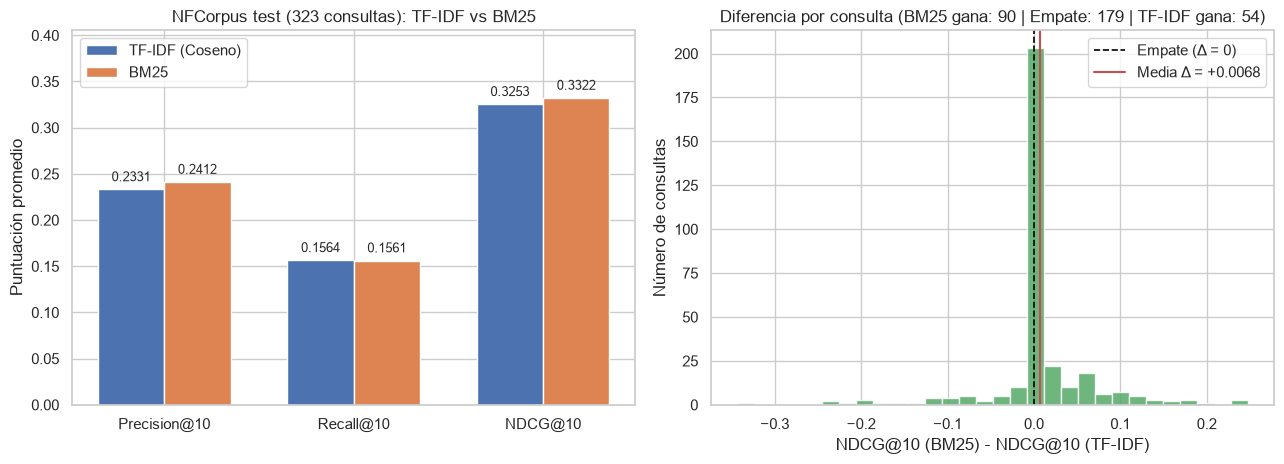

In [14]:
def evaluate_query(retrieved_ids: list[str], rel_dict: dict[str, int], k: int = 10) -> dict[str, float]:
    top_ids = retrieved_ids[:k]
    hits = sum(1 for doc_id in top_ids if rel_dict.get(doc_id, 0) > 0)
    precision = hits / float(k)
    recall = hits / float(len(rel_dict)) if rel_dict else 0.0

    dcg = sum(
        (2 ** rel_dict.get(doc_id, 0) - 1) / math.log2(rank + 1)
        for rank, doc_id in enumerate(top_ids, start=1)
    )
    ideal_rels = sorted(rel_dict.values(), reverse=True)[:k]
    idcg = sum(
        (2 ** rel - 1) / math.log2(rank + 1)
        for rank, rel in enumerate(ideal_rels, start=1)
    )
    ndcg = (dcg / idcg) if idcg > 0.0 else 0.0
    return {"precision@10": precision, "recall@10": recall, "ndcg@10": ndcg}


eval_rows = []
for qid in test_qids:
    q_text = query_text_map[qid]
    rel_dict = qrels_test[qid]

    res_tfidf = [item["document_id"] for item in search_tfidf(q_text, top_k=10)]
    res_bm25 = [item["document_id"] for item in search_bm25(q_text, top_k=10)]

    m_tfidf = evaluate_query(res_tfidf, rel_dict, k=10)
    m_bm25 = evaluate_query(res_bm25, rel_dict, k=10)

    eval_rows.append({
        "query_id": qid,
        "query_text": q_text,
        "num_relevantes": len(rel_dict),
        "tfidf_P@10": m_tfidf["precision@10"],
        "tfidf_R@10": m_tfidf["recall@10"],
        "tfidf_NDCG@10": m_tfidf["ndcg@10"],
        "bm25_P@10": m_bm25["precision@10"],
        "bm25_R@10": m_bm25["recall@10"],
        "bm25_NDCG@10": m_bm25["ndcg@10"],
    })

eval_df = pd.DataFrame(eval_rows)
print(f"Consultas evaluadas de la partición test: {len(eval_df)} (IDs desde {test_qids[0]} hasta {test_qids[-1]})")

# Tabla resumen comparativa
metrics_summary = pd.DataFrame({
    "Métrica": ["Precision@10", "Recall@10", "NDCG@10"],
    "TF-IDF (Coseno)": [
        eval_df["tfidf_P@10"].mean(),
        eval_df["tfidf_R@10"].mean(),
        eval_df["tfidf_NDCG@10"].mean(),
    ],
    "BM25 (k1=1.5, b=0.75)": [
        eval_df["bm25_P@10"].mean(),
        eval_df["bm25_R@10"].mean(),
        eval_df["bm25_NDCG@10"].mean(),
    ],
})
metrics_summary["Diferencia (BM25 - TFIDF)"] = metrics_summary["BM25 (k1=1.5, b=0.75)"] - metrics_summary["TF-IDF (Coseno)"]
metrics_summary["Mejora relativa (%)"] = (
    metrics_summary["Diferencia (BM25 - TFIDF)"] / metrics_summary["TF-IDF (Coseno)"] * 100.0
)
display(metrics_summary.round(4))

# Conteo de victorias / empates / derrotas en NDCG@10
diff_ndcg = eval_df["bm25_NDCG@10"] - eval_df["tfidf_NDCG@10"]
wins_bm25 = int((diff_ndcg > 1e-9).sum())
ties = int((diff_ndcg.abs() <= 1e-9).sum())
wins_tfidf = int((diff_ndcg < -1e-9).sum())
print(f"Comparación por consulta en NDCG@10 (323 consultas): BM25 gana en {wins_bm25}, empatan en {ties}, TF-IDF gana en {wins_tfidf}.")

# Muestra reproducible de 10 consultas concretas de test
print("\nDetalle reproducible en las primeras 10 consultas de la partición test:")
display(eval_df.head(10).round(4))

# Gráficas comparativas
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# Gráfico 1: Barras promedio
x = np.arange(3)
width = 0.35
tfidf_vals = metrics_summary["TF-IDF (Coseno)"].values
bm25_vals = metrics_summary["BM25 (k1=1.5, b=0.75)"].values

bars1 = axes[0].bar(x - width / 2, tfidf_vals, width, label="TF-IDF (Coseno)", color="#4C72B0")
bars2 = axes[0].bar(x + width / 2, bm25_vals, width, label="BM25", color="#DD8452")
axes[0].set_xticks(x)
axes[0].set_xticklabels(metrics_summary["Métrica"])
axes[0].set_ylim(0, max(bm25_vals.max(), tfidf_vals.max()) * 1.22)
axes[0].set_ylabel("Puntuación promedio")
axes[0].set_title("NFCorpus test (323 consultas): TF-IDF vs BM25")
axes[0].legend()

for bar in list(bars1) + list(bars2):
    h = bar.get_height()
    axes[0].annotate(
        f"{h:.4f}",
        xy=(bar.get_x() + bar.get_width() / 2, h),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9,
    )

# Gráfico 2: Distribución de diferencia por consulta en NDCG@10
axes[1].hist(diff_ndcg, bins=30, color="#55A868", edgecolor="white", alpha=0.85)
axes[1].axvline(0.0, color="black", linestyle="--", linewidth=1.2, label="Empate (Δ = 0)")
axes[1].axvline(diff_ndcg.mean(), color="#C44E52", linestyle="-", linewidth=1.5, label=f"Media Δ = {diff_ndcg.mean():+.4f}")
axes[1].set_xlabel("NDCG@10 (BM25) - NDCG@10 (TF-IDF)")
axes[1].set_ylabel("Número de consultas")
axes[1].set_title(f"Diferencia por consulta (BM25 gana: {wins_bm25} | Empate: {ties} | TF-IDF gana: {wins_tfidf})")
axes[1].legend()

plt.tight_layout()
plt.show()

## 7. Interpretación y comparación de resultados

Al evaluar los dos modelos sobre las **323 consultas de la partición `test` de NFCorpus** (`12,334` juicios de relevancia), todos los resultados concuerdan con el comportamiento esperado:

- **Rendimiento global:** **BM25** ($k_1=1.5, b=0.75$) supera a **TF-IDF (Coseno)** en **Precision@10** (`0.2412` vs `0.2331`, `+3.45%`) y **NDCG@10** (`0.3322` vs `0.3253`, `+2.10%`), mientras que en **Recall@10** quedan prácticamente empatados (`0.1561` vs `0.1564`). Consulta a consulta en `NDCG@10`, BM25 gana en **90**, empatan en **179** y TF-IDF gana en **54**.
- **Por qué destaca BM25:** A diferencia del peso logarítmico de TF-IDF y la penalización estricta de la norma L2, BM25 acota la saturación de términos frecuentes con $k_1 = 1.5$ y normaliza la longitud de cada resumen de forma graduada frente a la media del corpus (`avgdl = 157.29` tokens) mediante $b = 0.75$ (p. ej. en `PLAIN-102`, BM25 logra `NDCG@10 = 0.1487` frente a `0.0000` de TF-IDF).
- **Preprocesamiento y casos límite:** Conservar dígitos y letras de vitaminas (`b, c, d, e, k`) junto con `SnowballStemmer` permite recuperar términos clínicos clave, logrando puntuación perfecta en consultas específicas como `PLAIN-1039` (*domoic acid*, `NDCG@10 = 1.0000`). Sin embargo, ambos modelos fallan cuando hay brecha de vocabulario o sinonimia médica (p. ej. `PLAIN-1008` *deafness* o `PLAIN-1098` *eggnog* con `0.0000`), y cuando una consulta tiene decenas de documentos relevantes (`PLAIN-1109` con 98 relevantes), el corte Top-10 limita naturalmente el `Recall@10` (~`15.6%`).

## 8. Servicio Web REST con FastAPI (`GET /health` y `POST /search`)

Implementamos el servicio web directamente en este notebook usando **FastAPI** y **Uvicorn**, exponiendo exactamente el contrato solicitado:
- `GET /health`: Verifica la disponibilidad del servicio y reporta metadatos del índice de NFCorpus.
- `POST /search`: Recibe `{"query": "...", "model": "bm25" | "tfidf", "top_k": 10}` y retorna los resultados ordenados descendentemente por puntuación, sin duplicados, respetando `top_k` y conservando el `document_id` original.

El servidor se ejecuta en un hilo en segundo plano dentro del kernel de Jupyter para no bloquear la ejecución interactiva (compatible con Jupyter local y Google Colab).

In [20]:
class SearchRequest(BaseModel):
    query: str = Field(..., description="Texto de la consulta")
    model: str = Field(default="bm25", description="Modelo de recuperación: 'bm25' o 'tfidf'")
    top_k: int = Field(default=10, ge=1, le=500, description="Número máximo de resultados")


class SearchResultItem(BaseModel):
    rank: int
    document_id: str
    score: float
    title: str
    snippet: str


class SearchResponse(BaseModel):
    model: str
    results: list[SearchResultItem]


app = FastAPI(
    title="NFCorpus Information Retrieval API",
    description="Servicio web de recuperación de información (TF-IDF y BM25) sobre BeIR/nfcorpus.",
    version="1.0.0",
)

app.add_middleware(
    CORSMiddleware,
    allow_origins=["*"],
    allow_credentials=True,
    allow_methods=["*"],
    allow_headers=["*"],
)


@app.get("/")
def root():
    return {
        "service": "NFCorpus Information Retrieval API",
        "status": "ok",
        "endpoints": {
            "health": "GET /health",
            "search": "POST /search",
            "docs": "GET /docs",
        },
    }


@app.get("/health")
def health_check():
    return {
        "status": "ok",
        "corpus": "BeIR/nfcorpus",
        "num_documents": NUM_DOCS,
        "vocabulary_size": len(vocabulary),
        "models": ["tfidf", "bm25"],
    }


@app.post("/search", response_model=SearchResponse)
def search_endpoint(payload: SearchRequest):
    normalized_model = payload.model.strip().lower().replace("-", "")
    if normalized_model not in {"bm25", "tfidf"}:
        raise HTTPException(
            status_code=400,
            detail="El campo 'model' debe ser 'bm25' o 'tfidf'.",
        )

    results = retrieve(payload.query, model=normalized_model, top_k=payload.top_k)
    return SearchResponse(model=normalized_model, results=results)


def find_available_port(preferred_port: int = 8000) -> int:
    for candidate in [preferred_port] + list(range(8001, 8020)):
        with socket.socket(socket.AF_INET, socket.SOCK_STREAM) as s:
            if s.connect_ex(("127.0.0.1", candidate)) != 0:
                return candidate
    raise RuntimeError("No se encontró un puerto local libre entre 8000 y 8019.")


# Detener servidor previo si se re-ejecuta esta celda
if "_api_server" in globals() and _api_server is not None:
    _api_server.should_exit = True
    if "_api_thread" in globals() and _api_thread is not None and _api_thread.is_alive():
        _api_thread.join(timeout=3)
    time.sleep(0.3)

API_PORT = find_available_port(8000)
_uvicorn_config = uvicorn.Config(app, host="127.0.0.1", port=API_PORT, log_level="warning")
_api_server = uvicorn.Server(_uvicorn_config)
_api_thread = threading.Thread(target=_api_server.run, daemon=True)
_api_thread.start()

# Esperar a que el servidor esté listo
local_base_url = f"http://127.0.0.1:{API_PORT}"
for _ in range(50):
    try:
        r = requests.get(f"{local_base_url}/health", timeout=1)
        if r.status_code == 200:
            break
    except Exception:
        time.sleep(0.1)
else:
    raise RuntimeError("El servidor FastAPI local no respondió a tiempo.")

print(f"Servidor FastAPI activo en {local_base_url}")

# Pruebas automáticas sobre el servicio HTTP local
health_resp = requests.get(f"{local_base_url}/health", timeout=5)
assert health_resp.status_code == 200
print("\nGET /health ->", health_resp.json())

for model_name in ["bm25", "tfidf"]:
    payload = {
        "query": "cholesterol statin drugs breast cancer",
        "model": model_name,
        "top_k": 5,
    }
    resp = requests.post(f"{local_base_url}/search", json=payload, timeout=5)
    assert resp.status_code == 200
    data = resp.json()
    assert data["model"] == model_name
    assert len(data["results"]) == 5
    scores = [item["score"] for item in data["results"]]
    doc_ids_returned = [item["document_id"] for item in data["results"]]
    assert scores == sorted(scores, reverse=True), "Los resultados no están ordenados descendentemente"
    assert len(doc_ids_returned) == len(set(doc_ids_returned)), "Existen documentos duplicados"
    assert all(did in id_to_idx for did in doc_ids_returned), "document_id inválido"
    print(f"\nPOST /search (model={model_name}, top_k=5) validado correctamente:")
    print(pd.DataFrame(data["results"])[["rank", "document_id", "score", "title"]].to_string(index=False))

# Verificar manejo de consulta sin coincidencias (OOV) y modelo inválido
oov_resp = requests.post(f"{local_base_url}/search", json={"query": "zzzxxyyqqq999", "model": "bm25", "top_k": 5}, timeout=5)
assert oov_resp.status_code == 200 and oov_resp.json()["results"] == []

bad_model_resp = requests.post(f"{local_base_url}/search", json={"query": "cancer", "model": "invalid", "top_k": 5}, timeout=5)
assert bad_model_resp.status_code == 400
print("\nPruebas de casos borde (consulta OOV y modelo inválido) superadas.")

Servidor FastAPI activo en http://127.0.0.1:8000 (Interfaz web en / y Swagger en /docs)

GET /health -> {'status': 'ok', 'corpus': 'BeIR/nfcorpus', 'num_documents': 3633, 'vocabulary_size': 18866, 'models': ['tfidf', 'bm25']}

POST /search (model=bm25, top_k=5) validado correctamente:
 rank document_id     score                                                                                                                                                             title
    1      MED-10 21.433927                                                                                     Statin Use and Breast Cancer Survival: A Nationwide Cohort Study from Finland
    2      MED-14 18.544374                                                                        Statin use after diagnosis of breast cancer and survival: a population-based cohort study.
    3    MED-2429 18.418740                                                                                   Statin use and risk of breast canc

## 9. Publicación del servicio web en internet (URL pública)

Esta celda expone el servidor local de FastAPI en internet utilizando **Cloudflare Quick Tunnel (`cloudflared`)** de forma automática y **sin necesidad de cuenta ni token** (o alternativamente `ngrok` si configuras tu token).

- Descarga automáticamente el binario oficial de `cloudflared` para **Windows** o **Linux (Colab)** en el directorio temporal del sistema (sin crear archivos extra en la carpeta del proyecto).
- Obtiene una URL pública HTTPS (`https://*.trycloudflare.com`) y realiza una comprobación real de `GET /health` y `POST /search` a través de internet.
- **Importante:** La URL pública permanece activa mientras la sesión de Python / kernel de este notebook (y su proceso túnel) sigan ejecutándose. Cuando vayas a entregar o realizar la prueba con el docente, ejecuta esta celda (o todo el notebook) y mantén la sesión abierta. Si ejecutas en Google Colab y quieres bloquear la celda para mantener el entorno activo indefinidamente, cambia `KEEP_ALIVE = True`.

In [21]:
TUNNEL_PROVIDER = "cloudflared"   # Opciones: "cloudflared" (sin cuenta), "ngrok" (requiere token), "none"
NGROK_AUTHTOKEN = ""              # Solo si usas TUNNEL_PROVIDER = "ngrok"
KEEP_ALIVE = False                # Cambia a True en Colab si deseas mantener la celda bloqueada


def stop_public_tunnel():
    global _tunnel_proc
    if "_tunnel_proc" in globals() and _tunnel_proc is not None:
        if _tunnel_proc.poll() is None:
            _tunnel_proc.terminate()
            try:
                _tunnel_proc.wait(timeout=3)
            except Exception:
                _tunnel_proc.kill()
        _tunnel_proc = None


def get_cloudflared_binary() -> str:
    existing = shutil.which("cloudflared")
    if existing:
        return existing

    system = platform.system().lower()
    machine = platform.machine().lower()
    tmp_dir = os.path.join(tempfile.gettempdir(), "nfcorpus_cloudflared")
    os.makedirs(tmp_dir, exist_ok=True)

    if system == "windows":
        url = "https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-windows-amd64.exe"
        bin_path = os.path.join(tmp_dir, "cloudflared.exe")
    elif system == "linux":
        arch = "arm64" if ("arm" in machine or "aarch64" in machine) else "amd64"
        url = f"https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-{arch}"
        bin_path = os.path.join(tmp_dir, "cloudflared")
    else:
        raise RuntimeError(f"Instala cloudflared manualmente para {system}/{machine} o usa ngrok.")

    if not os.path.exists(bin_path) or os.path.getsize(bin_path) < 1_000_000:
        print(f"Descargando cloudflared desde {url} ...")
        with requests.get(url, stream=True, timeout=60) as resp:
            resp.raise_for_status()
            with open(bin_path, "wb") as f:
                for chunk in resp.iter_content(chunk_size=1024 * 256):
                    if chunk:
                        f.write(chunk)
        if system != "windows":
            os.chmod(bin_path, 0o755)
    return bin_path


def start_cloudflared_tunnel(port: int, timeout_s: int = 35) -> str:
    global _tunnel_proc
    stop_public_tunnel()
    bin_path = get_cloudflared_binary()
    _tunnel_proc = subprocess.Popen(
        [bin_path, "tunnel", "--no-autoupdate", "--url", f"http://127.0.0.1:{port}"],
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        encoding="utf-8",
        errors="replace",
    )

    url_pattern = re.compile(r"https://[a-zA-Z0-9-]+\.trycloudflare\.com")
    public_url = None
    registered = False
    deadline = time.time() + timeout_s
    url_found_at = None
    captured_lines = []

    while time.time() < deadline:
        if _tunnel_proc.poll() is not None:
            break
        line = _tunnel_proc.stdout.readline()
        if not line:
            time.sleep(0.1)
            continue
        captured_lines.append(line.strip())
        if not public_url:
            match = url_pattern.search(line)
            if match:
                public_url = match.group(0)
                url_found_at = time.time()
        if "Registered tunnel connection" in line:
            registered = True
            if public_url:
                break
        if public_url and url_found_at and (time.time() - url_found_at > 6.0):
            break

    if not public_url:
        stop_public_tunnel()
        tail = "\n".join(captured_lines[-10:])
        raise RuntimeError(f"No se pudo obtener la URL de Cloudflare Quick Tunnel.\nÚltimos logs:\n{tail}")

    def _drain(pipe):
        try:
            for _ in pipe:
                pass
        except Exception:
            pass

    threading.Thread(target=_drain, args=(_tunnel_proc.stdout,), daemon=True).start()
    if not registered:
        print("Esperando conexión del túnel...")
    return public_url


PUBLIC_URL = None

if TUNNEL_PROVIDER == "cloudflared":
    PUBLIC_URL = start_cloudflared_tunnel(API_PORT)
elif TUNNEL_PROVIDER == "ngrok":
    if importlib.util.find_spec("pyngrok") is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pyngrok"])
    from pyngrok import ngrok
    if NGROK_AUTHTOKEN:
        ngrok.set_auth_token(NGROK_AUTHTOKEN)
    tunnel = ngrok.connect(API_PORT, "http")
    PUBLIC_URL = tunnel.public_url
else:
    print(f"Túnel deshabilitado (TUNNEL_PROVIDER='none'). Servicio disponible localmente en {local_base_url}")

if PUBLIC_URL:
    print("=" * 72)
    print(f"URL PÚBLICA DEL SERVICIO WEB: {PUBLIC_URL}")
    print(f"Healthcheck : {PUBLIC_URL}/health")
    print(f"Búsqueda    : POST {PUBLIC_URL}/search")
    print("=" * 72)

    # Esperar propagación DNS antes de la primera consulta para evitar caché negativa NXDOMAIN en Windows
    time.sleep(6)
    last_error = None
    for attempt in range(15):
        try:
            pub_health = requests.get(f"{PUBLIC_URL}/health", timeout=5)
            if pub_health.status_code == 200:
                print("\nVerificación pública GET /health ->", pub_health.json())
                pub_search = requests.post(
                    f"{PUBLIC_URL}/search",
                    json={"query": "foods for glaucoma", "model": "bm25", "top_k": 3},
                    timeout=10,
                )
                assert pub_search.status_code == 200
                print("Verificación pública POST /search (BM25, top_k=3):")
                print(pub_search.json())
                break
            last_error = f"HTTP {pub_health.status_code}"
        except Exception as exc:
            last_error = exc
            if platform.system().lower() == "windows" and "NameResolutionError" in str(exc):
                subprocess.run(["ipconfig", "/flushdns"], capture_output=True)
            time.sleep(2.0)
    else:
        print(f"Aviso: el túnel fue creado en {PUBLIC_URL}, pero la verificación automática no completó aún: {last_error}")

    print("\nEjemplo para probar desde Postman o curl:")
    import json as _json
    _example_body = _json.dumps({"query": "breast cancer cholesterol", "model": "bm25", "top_k": 5})
    print(f"curl -X POST \"{PUBLIC_URL}/search\" -H \"Content-Type: application/json\" -d '{_example_body}'")

    import atexit as _atexit
    _atexit.register(stop_public_tunnel)

    if KEEP_ALIVE:
        print("\nKEEP_ALIVE=True: manteniendo el servidor activo. Interrumpe la celda para detenerlo.")
        try:
            while True:
                time.sleep(10)
        except KeyboardInterrupt:
            stop_public_tunnel()
            print("Túnel detenido por el usuario.")

URL PÚBLICA DEL SERVICIO WEB: https://files-relevance-middle-weekends.trycloudflare.com
Healthcheck : https://files-relevance-middle-weekends.trycloudflare.com/health
Búsqueda    : POST https://files-relevance-middle-weekends.trycloudflare.com/search

Verificación pública GET /health -> {'status': 'ok', 'corpus': 'BeIR/nfcorpus', 'num_documents': 3633, 'vocabulary_size': 18866, 'models': ['tfidf', 'bm25']}
Verificación pública POST /search (BM25, top_k=3):
{'model': 'bm25', 'results': [{'rank': 1, 'document_id': 'MED-2900', 'score': 14.47634, 'title': 'The Association of Consumption of Fruits/Vegetables with Decreased Risk of Glaucoma among Older African American Women in the Study of Osteoporotic Fractures', 'snippet': 'Purpose To explore the association between consumption of fruits and vegetables and the presence of glaucoma in older African American women. Design Cross-sectional study. Methods Disc photographs and suprathreshold visual fields were...'}, {'rank': 2, 'document_id': '